# Run and diagnose the remote ICESat-2 pipeline
Keep remote_parallel_blocks.py and diagnose_atl08_matching.py on your Python import path (for example, alongside this notebook). All functions live in those modules; this notebook only runs them.

For the current matching investigation, the defaults run the diagnostic for three overpasses at one site. Normal regression processing is off, so the same photons are not fetched twice. Nothing is saved automatically.


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os

sys.path.append(os.path.abspath(".."))

In [3]:
# %pip install "sliderule>=5.6,<6" icesat2db geopandas pyproj numpy pandas scipy scikit-learn matplotlib pyyaml
# Restart the kernel if upgrading SlideRule.

from pathlib import Path
import copy
import pandas as pd
import yaml
from IPython.display import display
from src.remote_parallel_blocks import load_sites, run_sites


## Settings
Set the processing YAML and selected-site table paths. SITE_INDICES is a list of row positions, for example [0, 2, 4]. MAX_RESOURCES is the number of overpasses **per site**: use SITE_INDICES=[0], MAX_RESOURCES=3 to compare three overpasses at the same site.

The date window must contain enough overpasses; fewer may be available. Explicit RESOURCES bypass date discovery.


In [10]:
PROCESSING_CONFIG_PATH = Path("../config.yaml")
SITES_PATH = Path("../../scratch/climate_site_selection/regional_site_selection/"\
                    "candidates_ce67aa33f7ea25a1/selection_aec51d75bae2d8e0/n09/selected_sites.csv")
START_TIME = "2018-10-01T00:00:00Z"
END_TIME = "2019-01-01T00:00:00Z"
LENGTH_M = 30
SITE_INDICES = [0]                # e.g. [0, 1, 2] for several sites.
MAX_RESOURCES = 3                 # Overpasses per site; None means all discovered.
RESOURCES = None                  # Or a list of explicit ATL03 resource names.
GRAPH_DETAIL = 1                  # Normal processing: Eg/Ev and regression fits.
RUN_PROCESSING = True            # Enable to run the normal pipeline.
RUN_MATCHING_DIAGNOSTIC = True    # Enable for the current investigation.
COMPARE_SOURCE_ATL08 = True       # Read selected fields directly from remote ATL08.
DIAGNOSTIC_BEAMS = ["gt1l", "gt1r", "gt2l", "gt2r", "gt3l", "gt3r"]
# Start with ["gt1l", "gt1r"] above for a shorter diagnostic.


## Load configuration and inspect sites
The selected site's exported boundaries define the analysis area. Your original processing configuration supplies the filters, block sizes and regression settings.


In [11]:
with PROCESSING_CONFIG_PATH.open() as stream:
    cfg = yaml.safe_load(stream)
remote_cfg = copy.deepcopy(cfg)
remote_cfg["parallel_blocks"]["rebinned"] = LENGTH_M
remote_cfg["parallel_blocks"]["DW"] = False  # Use ATL08 landcover for this remote run.

selected = load_sites(SITES_PATH)
display(selected[["site_id", "west", "south", "east", "north"]])


,site_id,west,south,east,north
0,S01,75.4,55.7,82.2,59.4
1,S02,48.4,62.9,57.0,66.6
2,S03,-151.1,62.0,-142.8,65.7
3,S04,116.5,68.3,127.2,72.0
4,S05,-62.1,48.5,-56.3,52.2
5,S06,115.6,53.0,121.9,56.7
6,S07,-104.7,53.0,-98.4,56.7
7,S08,115.5,59.3,123.1,63.0
8,S09,-77.0,54.8,-70.3,58.5


## Optional normal processing: every selected site and overpass
The loop replaces the old next(runs, None), which only consumed one result. It retains compact regression rows and diagnostics. The variable run refers to the last overpass for subsequent inspection; large segment tables are not accumulated.

All normal atmospheric/landcover filters still apply. For diagnosing matching alone, leave RUN_PROCESSING=False.


In [12]:
run = None
processing_summaries, result_tables = [], []
if RUN_PROCESSING:
    for run in run_sites(
        selected.iloc[SITE_INDICES], remote_cfg, START_TIME, END_TIME,
        resources=RESOURCES, max_resources=MAX_RESOURCES, graph_detail=GRAPH_DETAIL,
    ):
        print(run.site_id, run.resource)
        table = run.diagnostics.assign(site_id=run.site_id, resource=run.resource)
        processing_summaries.append(table)
        result_tables.append(run.results)
        display(table)
    results = pd.concat(result_tables, ignore_index=True) if result_tables else pd.DataFrame()
    processing_summary = pd.concat(processing_summaries, ignore_index=True) if processing_summaries else pd.DataFrame()
    display(processing_summary)


Warning, this environment is using an outdated client (v5.6.3). The code will run but some functionality supported by the server (v5.7.0) may not be available.


S01: 3 overpasses
  ATL03_20181014223522_02490106_007_01.h5


2026-10-23 16:42:22,533 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:42:27,632 - INFO - (dataframe.lua:138) <AppServer.1557> ATL03_20181014223522_02490106_007_01.h5/gt1l generated 157976 rows and 18 columns
2026-10-23 16:42:27,633 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181014223522_02490106_007_01.h5
2026-10-23 16:42:27,637 - INFO - Successfuly received 157976 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:42:27,896 - INFO - Writing output file: /tmp/tmpy9fitg2h
2026-10-23 16:42:29,452 - INFO - Closing output file: /tmp/tmpy9fitg2h
2026-10-23 16:42:38,928 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:42:42,537 - INFO - (dataframe.lua:138) <AppServer.72> ATL03_20181014223522_02490106_007_01.h5/gt1r generated 639801 rows and 18 columns
2026-10-23 16:42:42,538 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181014223522_02490106_007

S01 ATL03_20181014223522_02490106_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins,site_id,resource
0,gt1l,atmosphere_rejected,157976,6765,901,0,S01,ATL03_20181014223522_02490106_007_01.h5
1,gt1r,atmosphere_rejected,639801,9431,2156,0,S01,ATL03_20181014223522_02490106_007_01.h5
2,gt2l,atmosphere_rejected,170158,7170,769,0,S01,ATL03_20181014223522_02490106_007_01.h5
3,gt2r,atmosphere_rejected,404402,9357,1658,0,S01,ATL03_20181014223522_02490106_007_01.h5
4,gt3l,atmosphere_rejected,118013,6893,714,0,S01,ATL03_20181014223522_02490106_007_01.h5
5,gt3r,atmosphere_rejected,477708,9934,1718,0,S01,ATL03_20181014223522_02490106_007_01.h5


...

S01 ATL03_20181017095353_02870102_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins,site_id,resource
0,gt1l,atmosphere_rejected,409885,10014,2981,0,S01,ATL03_20181017095353_02870102_007_01.h5
1,gt1r,atmosphere_rejected,988834,13517,5435,0,S01,ATL03_20181017095353_02870102_007_01.h5
2,gt2l,atmosphere_rejected,452113,10164,2677,0,S01,ATL03_20181017095353_02870102_007_01.h5
3,gt2r,atmosphere_rejected,822913,13689,5083,0,S01,ATL03_20181017095353_02870102_007_01.h5
4,gt3l,atmosphere_rejected,342338,9920,3466,0,S01,ATL03_20181017095353_02870102_007_01.h5
5,gt3r,atmosphere_rejected,957956,13594,6112,0,S01,ATL03_20181017095353_02870102_007_01.h5


  ATL03_20181018222701_03100106_007_01.h5
S01 ATL03_20181018222701_03100106_007_01.h5


,beam,status,site_id,resource
0,gt1l,no_atl08,S01,ATL03_20181018222701_03100106_007_01.h5
1,gt1r,no_atl08,S01,ATL03_20181018222701_03100106_007_01.h5
2,gt2l,no_atl08,S01,ATL03_20181018222701_03100106_007_01.h5
3,gt2r,no_atl08,S01,ATL03_20181018222701_03100106_007_01.h5
4,gt3l,no_atl08,S01,ATL03_20181018222701_03100106_007_01.h5
5,gt3r,no_atl08,S01,ATL03_20181018222701_03100106_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins,site_id,resource
0,gt1l,atmosphere_rejected,157976.0,6765.0,901.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5
1,gt1r,atmosphere_rejected,639801.0,9431.0,2156.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5
2,gt2l,atmosphere_rejected,170158.0,7170.0,769.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5
3,gt2r,atmosphere_rejected,404402.0,9357.0,1658.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5
4,gt3l,atmosphere_rejected,118013.0,6893.0,714.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5
5,gt3r,atmosphere_rejected,477708.0,9934.0,1718.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5
6,gt1l,atmosphere_rejected,409885.0,10014.0,2981.0,0.0,S01,ATL03_20181017095353_02870102_007_01.h5
7,gt1r,atmosphere_rejected,988834.0,13517.0,5435.0,0.0,S01,ATL03_20181017095353_02870102_007_01.h5
8,gt2l,atmosphere_rejected,452113.0,10164.0,2677.0,0.0,S01,ATL03_20181017095353_02870102_007_01.h5
9,gt2r,atmosphere_rejected,822913.0,13689.0,5083.0,0.0,S01,ATL03_20181017095353_02870102_007_01.h5


## Inspect the last normal-processing overpass
This table is only available when RUN_PROCESSING=True.


In [13]:
if run is not None and not run.segments.empty:
    display(run.segments[[
        "beam", "bin_id", "photon_rate_te", "photon_rate_can_nr",
        "msw_flag", "layer_flag", "segment_landcover", "canopy_openness",
        "canopy_openness_resolution_m", "atl08_matched",
        "atl08_parent_count", "atl08_parent_fraction", "used_for_processing",
    ]].head(20))


## Diagnose matching across sites and overpasses
The diagnostic uses the same photon selection, 30 m bins, representative photon and matching rules as the pipeline, but **does not discard beams for atmosphere or run regression**.

It also reads a few 1D fields from the remote ATL08 granule. These are selected arrays, not full HDF5 downloads. This extra source check distinguishes missing database-query parents from ID/time matching failures. It reports the exact companion filename checked; its revision is not guaranteed to be the same as the companion selected internally by SlideRule's photon request.

Compact diagnostic tables are retained below; photon tables are discarded after each beam. Network errors are recorded explicitly and the diagnostic continues, so failure does not masquerade as zero coverage.


2026-10-23 16:50:48,775 - WARNING - Warning, this environment is using an outdated client (v5.6.3). The code will run but some functionality supported by the server (v5.7.0) may not be available.


S01: diagnosing 3 overpasses
  ATL03_20181014223522_02490106_007_01.h5
    Source check: ATL08_20181014223522_02490106_007_01.h5
    gt1l


2026-10-23 16:51:00,858 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:51:01,341 - INFO - (dataframe.lua:138) <AppServer.38> ATL03_20181014223522_02490106_007_01.h5/gt1l generated 157976 rows and 18 columns
2026-10-23 16:51:01,342 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181014223522_02490106_007_01.h5
2026-10-23 16:51:01,343 - INFO - Successfuly received 157976 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:51:01,605 - INFO - Writing output file: /tmp/tmpvbzz7xnf
2026-10-23 16:51:10,047 - INFO - Closing output file: /tmp/tmpvbzz7xnf


    gt1r


2026-10-23 16:51:12,507 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:51:15,377 - INFO - (dataframe.lua:138) <AppServer.14> ATL03_20181014223522_02490106_007_01.h5/gt1r generated 639801 rows and 18 columns
2026-10-23 16:51:15,377 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181014223522_02490106_007_01.h5
2026-10-23 16:51:15,378 - INFO - Successfuly received 639801 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:51:16,080 - INFO - Writing output file: /tmp/tmpi2y_sv9c
2026-10-23 16:51:21,103 - INFO - Closing output file: /tmp/tmpi2y_sv9c


...

    gt3l


2026-10-23 16:51:34,807 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:51:35,787 - INFO - (dataframe.lua:138) <AppServer.138> ATL03_20181014223522_02490106_007_01.h5/gt3l generated 118013 rows and 18 columns
2026-10-23 16:51:35,788 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181014223522_02490106_007_01.h5
2026-10-23 16:51:35,789 - INFO - Successfuly received 118013 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:51:35,790 - INFO - Writing output file: /tmp/tmpg59yamd7
2026-10-23 16:51:36,696 - INFO - Closing output file: /tmp/tmpg59yamd7


    gt3r


2026-10-23 16:51:38,447 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:51:42,027 - INFO - (dataframe.lua:138) <AppServer.120> ATL03_20181014223522_02490106_007_01.h5/gt3r generated 477708 rows and 18 columns
2026-10-23 16:51:42,028 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181014223522_02490106_007_01.h5
2026-10-23 16:51:42,029 - INFO - Successfuly received 477708 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:51:42,431 - INFO - Writing output file: /tmp/tmphjsn7g6b
2026-10-23 16:51:44,448 - INFO - Closing output file: /tmp/tmphjsn7g6b


,site_id,resource,beam,status,bins,matched_pct,signal_bins,signal_matched_pct,representative_time_rejected_bins,representative_miss_with_other_photon_match,source_parent_missing_from_db_bins,source_check_status,source_check_error
0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l,ok,6765,13.318551,3072,29.329427,0,90,1286,ok,None
1,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r,ok,9431,22.860778,3579,60.240291,0,97,990,ok,None
2,S01,ATL03_20181014223522_02490106_007_01.h5,gt2l,ok,7170,10.725244,2415,31.842650,0,80,1089,ok,None
3,S01,ATL03_20181014223522_02490106_007_01.h5,gt2r,ok,9357,17.719354,2767,59.920492,0,85,664,ok,None
4,S01,ATL03_20181014223522_02490106_007_01.h5,gt3l,ok,6893,10.358335,2518,28.355838,1,57,979,ok,None
5,S01,ATL03_20181014223522_02490106_007_01.h5,gt3r,ok,9934,17.294141,2935,58.534923,2,75,943,ok,None


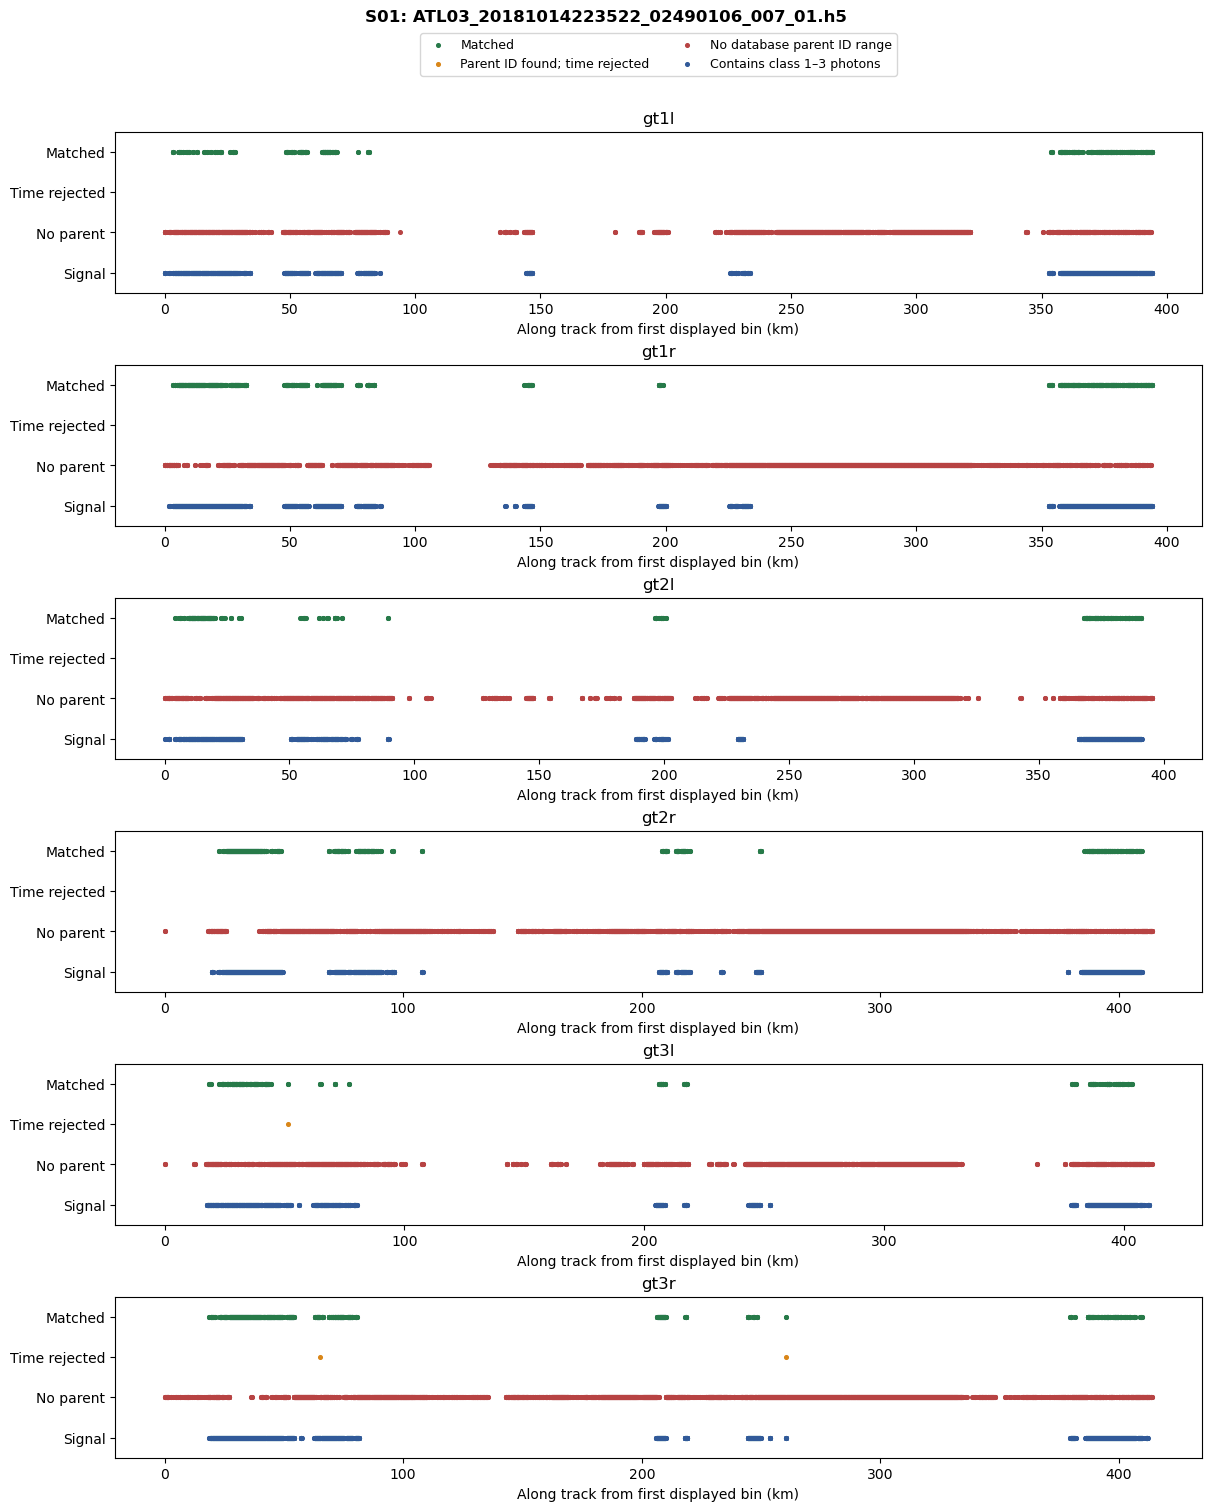

  ATL03_20181017095353_02870102_007_01.h5
    Source check: ATL08_20181017095353_02870102_007_01.h5
    gt1l


2026-10-23 16:51:53,207 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:51:54,737 - INFO - (dataframe.lua:138) <AppServer.226> ATL03_20181017095353_02870102_007_01.h5/gt1l generated 409885 rows and 18 columns
2026-10-23 16:51:54,738 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181017095353_02870102_007_01.h5
2026-10-23 16:51:54,739 - INFO - Successfuly received 409885 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:51:55,133 - INFO - Writing output file: /tmp/tmpgxt7t03w
2026-10-23 16:51:57,262 - INFO - Closing output file: /tmp/tmpgxt7t03w


    gt1r


2026-10-23 16:51:59,697 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:52:05,517 - INFO - (dataframe.lua:138) <AppServer.2088> ATL03_20181017095353_02870102_007_01.h5/gt1r generated 988834 rows and 18 columns
2026-10-23 16:52:05,518 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181017095353_02870102_007_01.h5
2026-10-23 16:52:05,519 - INFO - Successfuly received 988834 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:52:06,704 - INFO - Writing output file: /tmp/tmpnpegumfi
2026-10-23 16:52:09,777 - INFO - Closing output file: /tmp/tmpnpegumfi


    gt2l


...

    gt3l


2026-10-23 16:52:29,378 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:52:31,087 - INFO - (dataframe.lua:138) <AppServer.2513> ATL03_20181017095353_02870102_007_01.h5/gt3l generated 342338 rows and 18 columns
2026-10-23 16:52:31,088 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181017095353_02870102_007_01.h5
2026-10-23 16:52:31,088 - INFO - Successfuly received 342338 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:52:31,497 - INFO - Writing output file: /tmp/tmpq5m_vs3a
2026-10-23 16:52:33,374 - INFO - Closing output file: /tmp/tmpq5m_vs3a


    gt3r


2026-10-23 16:52:35,677 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:52:37,647 - INFO - (dataframe.lua:138) <AppServer.2544> ATL03_20181017095353_02870102_007_01.h5/gt3r generated 957956 rows and 18 columns
2026-10-23 16:52:37,648 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181017095353_02870102_007_01.h5
2026-10-23 16:52:37,648 - INFO - Successfuly received 957956 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:52:38,997 - INFO - Writing output file: /tmp/tmptbdlktdg
2026-10-23 16:52:42,149 - INFO - Closing output file: /tmp/tmptbdlktdg


,site_id,resource,beam,status,bins,matched_pct,signal_bins,signal_matched_pct,representative_time_rejected_bins,representative_miss_with_other_photon_match,source_parent_missing_from_db_bins,source_check_status,source_check_error
0,S01,ATL03_20181017095353_02870102_007_01.h5,gt1l,ok,10014,29.768324,8853,33.660906,79,321,3018,ok,None
1,S01,ATL03_20181017095353_02870102_007_01.h5,gt1r,ok,13517,40.208626,9875,55.037975,36,279,3560,ok,None
2,S01,ATL03_20181017095353_02870102_007_01.h5,gt2l,ok,10164,26.338056,9001,29.741140,62,328,3788,ok,None
3,S01,ATL03_20181017095353_02870102_007_01.h5,gt2r,ok,13689,37.132004,9949,51.090562,26,267,3795,ok,None
4,S01,ATL03_20181017095353_02870102_007_01.h5,gt3l,ok,9920,34.939516,9082,38.163400,78,402,2836,ok,None
5,S01,ATL03_20181017095353_02870102_007_01.h5,gt3r,ok,13594,44.961012,9985,61.211818,24,286,3220,ok,None


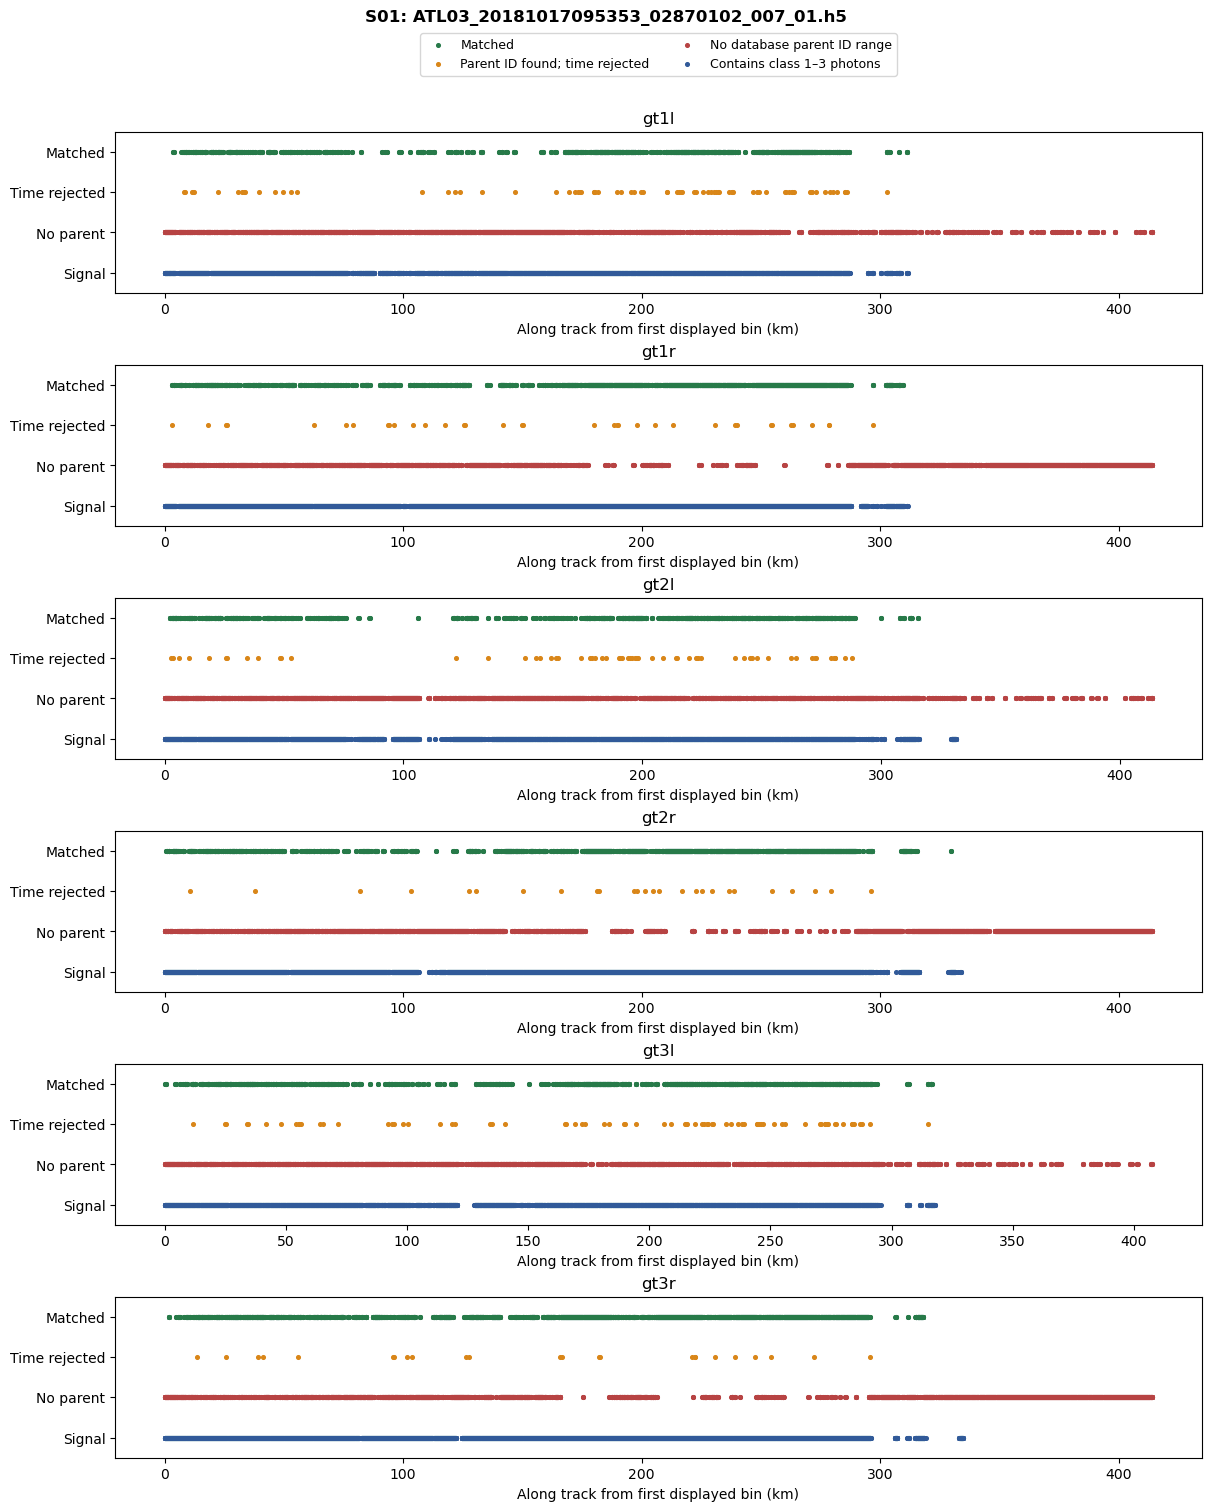

  ATL03_20181018222701_03100106_007_01.h5
    Source check: ATL08_20181018222701_03100106_007_01.h5
    gt1l


2026-10-23 16:52:51,047 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:52:51,659 - INFO - (dataframe.lua:138) <AppServer.2268> ATL03_20181018222701_03100106_007_01.h5/gt1l generated 25 rows and 18 columns
2026-10-23 16:52:51,824 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181018222701_03100106_007_01.h5
2026-10-23 16:52:51,825 - INFO - Successfuly received 25 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:52:51,826 - INFO - Writing output file: /tmp/tmpy4sgfjfl
2026-10-23 16:52:51,829 - INFO - Closing output file: /tmp/tmpy4sgfjfl


    gt1r


2026-10-23 16:52:53,788 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:52:54,618 - INFO - (dataframe.lua:138) <AppServer.2281> ATL03_20181018222701_03100106_007_01.h5/gt1r generated 713 rows and 18 columns
2026-10-23 16:52:54,623 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181018222701_03100106_007_01.h5
2026-10-23 16:52:54,624 - INFO - Successfuly received 713 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:52:54,625 - INFO - Writing output file: /tmp/tmp0a20ygl_
2026-10-23 16:52:54,628 - INFO - Closing output file: /tmp/tmp0a20ygl_


    gt2l


...

    gt3l


2026-10-23 16:53:02,178 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:53:02,746 - INFO - (dataframe.lua:138) <AppServer.493> ATL03_20181018222701_03100106_007_01.h5/gt3l generated 63 rows and 18 columns
2026-10-23 16:53:02,747 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181018222701_03100106_007_01.h5
2026-10-23 16:53:02,749 - INFO - Successfuly received 63 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:53:02,754 - INFO - Writing output file: /tmp/tmprlq9jgbn
2026-10-23 16:53:02,756 - INFO - Closing output file: /tmp/tmprlq9jgbn


    gt3r


2026-10-23 16:53:04,578 - INFO - Starting proxy for atl03x to process 1 resource(s) with 1 thread(s)
2026-10-23 16:53:07,189 - INFO - (dataframe.lua:138) <AppServer.1304> ATL03_20181018222701_03100106_007_01.h5/gt3r generated 618 rows and 18 columns
2026-10-23 16:53:07,190 - INFO - Successfully completed processing resource [1 out of 1]: ATL03_20181018222701_03100106_007_01.h5
2026-10-23 16:53:07,527 - INFO - Successfuly received 618 x 24 dataframe (eofs=1, dups=0, ptls=0)
2026-10-23 16:53:07,528 - INFO - Writing output file: /tmp/tmphbq2p7io
2026-10-23 16:53:07,531 - INFO - Closing output file: /tmp/tmphbq2p7io


,site_id,resource,beam,status,bins,matched_pct,signal_bins,signal_matched_pct,representative_time_rejected_bins,representative_miss_with_other_photon_match,source_parent_missing_from_db_bins,source_check_status,source_check_error
0,S01,ATL03_20181018222701_03100106_007_01.h5,gt1l,ok,1,0.0,0,NaN,0,0,0,ok,None
1,S01,ATL03_20181018222701_03100106_007_01.h5,gt1r,ok,489,0.0,0,NaN,0,0,0,ok,None
2,S01,ATL03_20181018222701_03100106_007_01.h5,gt2l,ok,2,0.0,0,NaN,0,0,0,ok,None
3,S01,ATL03_20181018222701_03100106_007_01.h5,gt2r,ok,582,0.0,0,NaN,0,0,0,ok,None
4,S01,ATL03_20181018222701_03100106_007_01.h5,gt3l,ok,2,0.0,0,NaN,0,0,0,ok,None
5,S01,ATL03_20181018222701_03100106_007_01.h5,gt3r,ok,438,0.0,0,NaN,0,0,0,ok,None


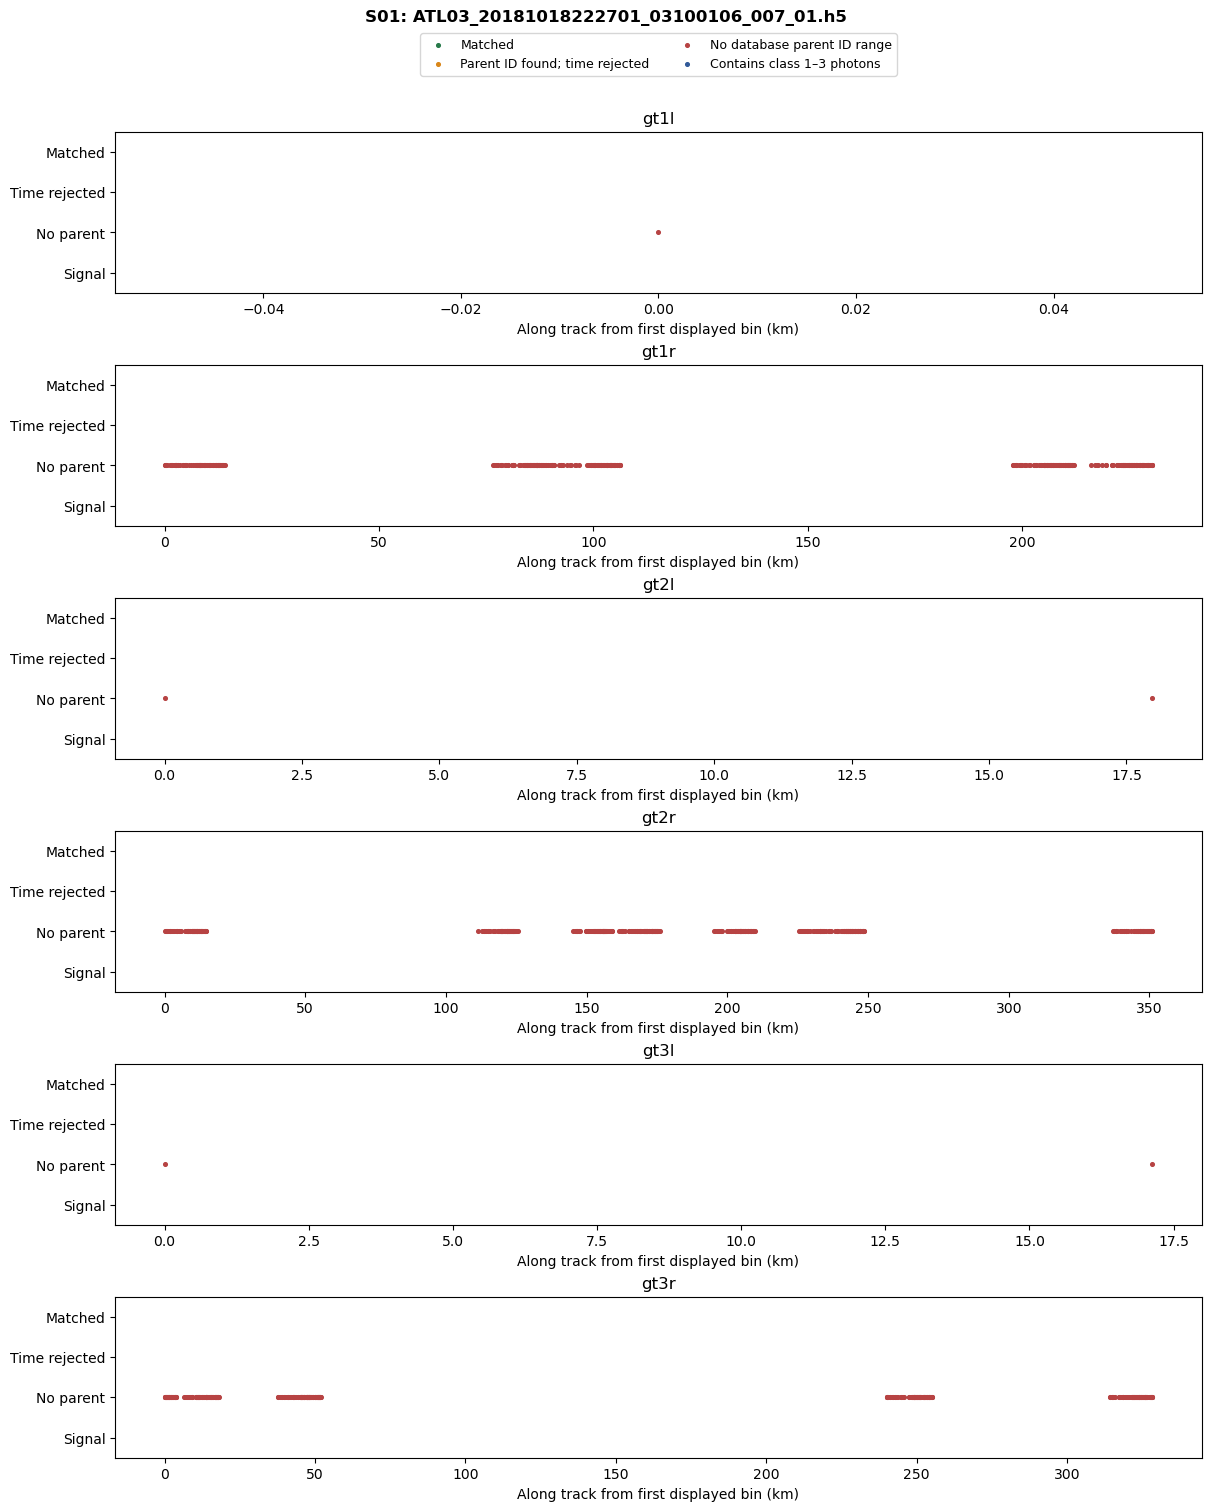

In [16]:
diagnostic_reports = []
if RUN_MATCHING_DIAGNOSTIC:
    from src.diagnose_atl08_matching import diagnose_sites, plot_matching
    for report in diagnose_sites(
        selected.iloc[SITE_INDICES], START_TIME, END_TIME,
        length=LENGTH_M, resources=RESOURCES, max_resources=MAX_RESOURCES,
        beams=DIAGNOSTIC_BEAMS, compare_source=COMPARE_SOURCE_ATL08,
        cfg=remote_cfg,
    ):
        diagnostic_reports.append(report)
        columns = ["site_id", "resource", "beam", "status", "bins", "matched_pct",
                   "signal_bins", "signal_matched_pct", "representative_time_rejected_bins",
                   "representative_miss_with_other_photon_match", "source_parent_missing_from_db_bins",
                   "source_check_status", "error", "source_check_error"]
        display(report.summary[[x for x in columns if x in report.summary]])
        plot_matching(report)
    matching_summary = pd.concat([r.summary for r in diagnostic_reports], ignore_index=True) if diagnostic_reports else pd.DataFrame()


## Compare the overpasses
- matched_pct: matched fraction of **all occupied bins**, including noise-only bins.
- signal_matched_pct: matched fraction of bins containing at least one ground/canopy/top-of-canopy photon.
- representative_time_rejected_bins: the representative photon's segment ID fits a database parent, but its time fails the current check.
- representative_miss_with_other_photon_match: the representative fails, although another photon in its bin matches. No alternative assignment is applied.
- source_parent_missing_from_db_bins: a source ATL08 parent covers the representative photon ID, but that parent is absent from the database-query result.

An absent value means that comparison was unavailable, often because the source read failed. It does not mean zero. Source-only parents outside the query bounds are counted separately from source-only parents inside them.


In [17]:
if RUN_MATCHING_DIAGNOSTIC and not matching_summary.empty:
    columns = ["site_id", "resource", "beam", "status", "matched_pct", "signal_matched_pct",
               "no_signal_bins", "representative_time_rejected_bins",
               "source_parents_in_query_missing_from_db", "source_check_status"]
    display(matching_summary[[x for x in columns if x in matching_summary]])


,site_id,resource,beam,status,matched_pct,signal_matched_pct,no_signal_bins,representative_time_rejected_bins,source_parents_in_query_missing_from_db,source_check_status
0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l,ok,13.318551,29.329427,3693,0,392,ok
1,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r,ok,22.860778,60.240291,5852,0,302,ok
2,S01,ATL03_20181014223522_02490106_007_01.h5,gt2l,ok,10.725244,31.842650,4755,0,334,ok
3,S01,ATL03_20181014223522_02490106_007_01.h5,gt2r,ok,17.719354,59.920492,6590,0,202,ok
4,S01,ATL03_20181014223522_02490106_007_01.h5,gt3l,ok,10.358335,28.355838,4375,1,298,ok
5,S01,ATL03_20181014223522_02490106_007_01.h5,gt3r,ok,17.294141,58.534923,6999,2,285,ok
6,S01,ATL03_20181017095353_02870102_007_01.h5,gt1l,ok,29.768324,33.660906,1161,79,909,ok
7,S01,ATL03_20181017095353_02870102_007_01.h5,gt1r,ok,40.208626,55.037975,3642,36,1066,ok
8,S01,ATL03_20181017095353_02870102_007_01.h5,gt2l,ok,26.338056,29.741140,1163,62,1148,ok
9,S01,ATL03_20181017095353_02870102_007_01.h5,gt2r,ok,37.132004,51.090562,3740,26,1146,ok


## Detailed diagnosis for one overpass
Choose REPORT_INDEX from the order displayed above. Each report contains all requested beams.

1. Bin reasons show whether IDs or times failed and how many affected bins contain signal.
2. Class counts show whether ground/canopy photons match better than noise/unclassified photons.
3. Query audit shows records removed by track/cycle/source-filename selection.
4. Field comparison checks database values against the source ATL08 fields for common parent IDs. Time differences here could explain failures of the time check.
5. Missing-source-parent examples show source heights and flags. Invalid heights, water or urban flags are possible clues to ingestion filtering; they do not prove which filters the public archive used.

The atmospheric mean and thresholds are also in report.summary, but do not alter these matching statistics.


In [18]:
REPORT_INDEX = 0
if diagnostic_reports:
    report = diagnostic_reports[REPORT_INDEX]
    display(report.summary)
    display(report.bin_reasons)
    display(report.by_class)
    display(report.query_audit)
    display(report.field_comparison)
    display(report.examples.head(20))
    if not report.parent_comparison.empty:
        missing = report.parent_comparison[
            report.parent_comparison.membership.eq("source_only") &
            report.parent_comparison.source_center_in_query.eq(True)
        ]
        columns = ["beam", "segment_id_beg", "segment_id_end_source", "h_te_best_fit_source",
                   "h_canopy_source", "urban_flag_source", "segment_watermask_source",
                   "source_invalid_terrain_height", "source_invalid_canopy_height"]
        display(missing[[x for x in columns if x in missing]].head(20))


,status,photons_returned,photons_in_analysis_bins,database_parents,bins,matched_bins,matched_pct,signal_bins,signal_matched_bins,signal_matched_pct,...,missing_db_parents_with_source_invalid_canopy_height,msw_flag_passes_beam_check,layer_flag_passes_beam_check,site_id,resource,beam,source_check_status,source_resource,source_candidates,source_check_error
0,ok,157976,157241,271,6765,901,13.318551,3072,901,29.329427,...,390,False,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l,ok,ATL08_20181014223522_02490106_007_01.h5,1,None
1,ok,639801,636785,647,9431,2156,22.860778,3579,2156,60.240291,...,300,False,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r,ok,ATL08_20181014223522_02490106_007_01.h5,1,None
2,ok,170158,170158,232,7170,769,10.725244,2415,769,31.842650,...,330,False,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt2l,ok,ATL08_20181014223522_02490106_007_01.h5,1,None
3,ok,404402,404381,499,9357,1658,17.719354,2767,1658,59.920492,...,201,False,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt2r,ok,ATL08_20181014223522_02490106_007_01.h5,1,None
4,ok,118013,118013,216,6893,714,10.358335,2518,714,28.355838,...,297,False,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt3l,ok,ATL08_20181014223522_02490106_007_01.h5,1,None
5,ok,477708,477701,515,9934,1718,17.294141,2935,1718,58.534923,...,280,False,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt3r,ok,ATL08_20181014223522_02490106_007_01.h5,1,None


,reason,bins,signal_bins,percent_all_bins,percent_signal_bins,site_id,resource,beam
0,before_first_parent,39,23,0.576497,0.748698,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
1,matched,901,901,13.318551,29.329427,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
2,segment_gap,5825,2148,86.104952,69.921875,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
3,before_first_parent,71,10,0.752836,0.279408,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r
4,matched,2156,2156,22.860778,60.240291,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r
5,segment_gap,7204,1413,76.386385,39.480302,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r
6,before_first_parent,71,21,0.990237,0.869565,S01,ATL03_20181014223522_02490106_007_01.h5,gt2l
7,matched,769,769,10.725244,31.842650,S01,ATL03_20181014223522_02490106_007_01.h5,gt2l
8,segment_gap,6228,1623,86.861925,67.204969,S01,ATL03_20181014223522_02490106_007_01.h5,gt2l
9,after_last_parent,102,2,1.422594,0.082816,S01,ATL03_20181014223522_02490106_007_01.h5,gt2l


,classification,photons,id_matched,strict_matched,class_name,strict_match_pct,source_id_matched,site_id,resource,beam
0,0,3394,1514,1514,noise,44.608132,3016,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
1,1,91290,32153,32153,ground,35.220725,87437,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
2,2,13519,7983,7983,canopy,59.050226,12584,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
3,3,2549,2108,2108,top_of_canopy,82.699098,2345,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
4,4,46489,674,670,unclassified,1.441201,1539,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
5,0,15160,11251,11251,noise,74.215040,14729,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r
6,1,363388,228894,228894,ground,62.988871,360193,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r
7,2,60294,51354,51354,canopy,85.172654,59412,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r
8,3,13641,12660,12660,top_of_canopy,92.808445,13466,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r
9,4,184302,2230,2227,unclassified,1.208343,3600,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r


,stage,rows,site_id,resource
0,database_query,2380,S01,ATL03_20181014223522_02490106_007_01.h5
1,correct_rgt,2380,S01,ATL03_20181014223522_02490106_007_01.h5
2,correct_rgt_and_cycle,2380,S01,ATL03_20181014223522_02490106_007_01.h5
3,parents_gt1l,271,S01,ATL03_20181014223522_02490106_007_01.h5
4,parents_gt1r,647,S01,ATL03_20181014223522_02490106_007_01.h5
5,parents_gt2l,232,S01,ATL03_20181014223522_02490106_007_01.h5
6,parents_gt2r,499,S01,ATL03_20181014223522_02490106_007_01.h5
7,parents_gt3l,216,S01,ATL03_20181014223522_02490106_007_01.h5
8,parents_gt3r,515,S01,ATL03_20181014223522_02490106_007_01.h5


,field,compared,exact_mismatches,median_db_minus_source,max_absolute_difference,site_id,resource,beam
0,segment_id_end,271,0,0.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
1,delta_time_beg,271,0,0.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
2,delta_time_end,271,0,0.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
3,longitude,271,0,0.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
4,latitude,271,0,0.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
5,h_te_best_fit,271,0,0.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
6,msw_flag,271,0,0.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
7,layer_flag,271,0,0.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
8,segment_id_end,647,0,0.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r
9,delta_time_beg,647,0,0.0,0.0,S01,ATL03_20181014223522_02490106_007_01.h5,gt1r


,bin_id,longitude,latitude,n_photons,n_signal,id_matched_photons,strict_matched_photons,reason,matched,id_match,...,edge_bin,length_m,x_mid_m,source_id_match,source_strict_match,source_parent_start,source_parent_missing_from_db,site_id,resource,beam
0,449061,77.773464,59.221544,1,1,0,0,before_first_parent,False,False,...,True,30,13471845.0,False,False,NaN,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
1,449062,77.773415,59.221301,3,3,0,0,before_first_parent,False,False,...,False,30,13471875.0,False,False,NaN,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
2,449063,77.773354,59.220996,12,12,0,0,before_first_parent,False,False,...,False,30,13471905.0,False,False,NaN,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
3,449064,77.773306,59.220752,16,15,0,0,before_first_parent,False,False,...,False,30,13471935.0,True,True,672599.0,True,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
4,449065,77.773250,59.220469,14,13,0,0,before_first_parent,False,False,...,False,30,13471965.0,True,True,672599.0,True,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
5,449178,77.767199,59.190236,4,4,0,0,segment_gap,False,False,...,False,30,13475355.0,False,False,NaN,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
6,449179,77.767134,59.189925,7,6,0,0,segment_gap,False,False,...,False,30,13475385.0,False,False,NaN,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
7,449180,77.767090,59.189703,6,6,0,0,segment_gap,False,False,...,False,30,13475415.0,False,False,NaN,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
8,449181,77.767032,59.189410,2,0,0,0,segment_gap,False,False,...,False,30,13475445.0,False,False,NaN,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l
9,449182,77.766992,59.189200,1,0,0,0,segment_gap,False,False,...,False,30,13475475.0,False,False,NaN,False,S01,ATL03_20181014223522_02490106_007_01.h5,gt1l


,beam,segment_id_beg,segment_id_end_source,h_te_best_fit_source,h_canopy_source,urban_flag_source,segment_watermask_source,source_invalid_terrain_height,source_invalid_canopy_height
0,gt1l,672599,672603,32.958683,3.402823e+38,0,0,False,True
1,gt1l,672684,672688,26.961845,3.402823e+38,0,0,False,True
2,gt1l,672689,672692,27.023121,3.402823e+38,0,0,False,True
3,gt1l,672756,672758,30.646027,3.402823e+38,0,0,False,True
6,gt1l,672789,672793,26.014229,3.402823e+38,0,0,False,True
7,gt1l,672804,672808,31.211170,3.402823e+38,0,0,False,True
8,gt1l,672814,672818,31.595558,3.402823e+38,0,0,False,True
9,gt1l,672824,672828,31.190878,3.402823e+38,0,0,False,True
10,gt1l,672840,672843,26.073824,3.402823e+38,0,0,False,True
11,gt1l,672859,672863,31.071011,3.402823e+38,0,0,False,True
